# Human vs AI Essays: Data Visualization
**Task 3 - Data Visualization**

This notebook looks at a dataset of student essays, some written by humans and some written by AI (large language models). The question I want to answer is simple: **do human essays and AI essays look different?** I'll make features from the text and use charts to compare the two groups.

**Dataset:** DAIGT "LLM - Detect AI Generated Text" essays (train_v2_drcat_02, from Kaggle). I took a random sample of 6,000 essays (random_state=42) so the notebook runs fast. In the data, `generated = 0` means human and `generated = 1` means AI.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, os
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

sns.set_style('whitegrid')
colors = {'Human': '#1f77b4', 'AI': '#ff7f0e'}   # blue = human, orange = AI
os.makedirs('images', exist_ok=True)

## 1. Load the data and take a quick look

In [2]:
df = pd.read_csv('human_vs_ai_essays_sample.csv')
print(df.shape)
df.head()

(6000, 2)


,text,generated
0,"Ummm... hey there! So, like, I know it's kind...",1
1,"Dear Principal,\n\nAs you may know, many stude...",0
2,The cafeteria at our school is an important re...,1
3,Some schools require students to complete summ...,0
4,When considering the advantages and disadvanta...,1


In [3]:
df.info()
print('Missing values:')
print(df.isnull().sum())
print('Duplicates:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   text       6000 non-null   str  
 1   generated  6000 non-null   int64
dtypes: int64(1), str(1)
memory usage: 93.9 KB
Missing values:
text         0
generated    0
dtype: int64
Duplicates: 0


In [4]:
# minimum cleaning: drop empty rows and duplicates
df = df.dropna().drop_duplicates()
df['label'] = df['generated'].map({0: 'Human', 1: 'AI'})
print(df['label'].value_counts())

label
Human    3616
AI       2384
Name: count, dtype: int64


Cleaning was small: I dropped missing rows and duplicates, then made a readable `label` column (Human / AI).

## 2. Make some simple features from the text

In [5]:
df['char_count'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()
df['sentence_count'] = df['text'].str.count(r'[.!?]+')
df['avg_word_len'] = df['char_count'] / df['word_count']
df['comma_count'] = df['text'].str.count(',')
df['unique_ratio'] = df['text'].apply(lambda t: len(set(t.lower().split())) / len(t.split()))
df['avg_sentence_len'] = df['word_count'] / df['sentence_count'].replace(0, 1)

features = ['word_count', 'char_count', 'sentence_count', 'avg_word_len', 'comma_count', 'unique_ratio']
df.groupby('label')[features].mean().round(2)

,word_count,char_count,sentence_count,avg_word_len,comma_count,unique_ratio
label,,,,,,
AI,330.34,2016.81,18.1,6.15,19.76,0.51
Human,419.27,2352.00,21.3,5.59,14.28,0.48


## 3. How many human vs AI essays?

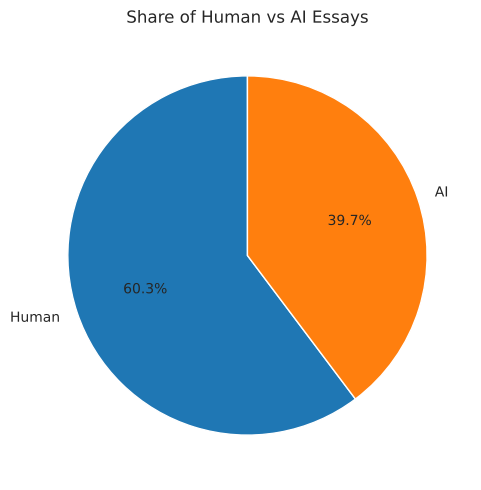

In [6]:
counts = df['label'].value_counts()
plt.figure(figsize=(6, 5))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', colors=[colors[l] for l in counts.index], startangle=90)
plt.title('Share of Human vs AI Essays')
plt.tight_layout()
plt.savefig('images/01_class_split.png', dpi=150)
plt.show()

**What it shows:** the split between human and AI essays in the sample. **Insight:** humans make up about 60% of the essays, so the data is not perfectly balanced but is close enough to compare fairly. **Use:** any detector built on this data should be checked with more than plain accuracy because of the imbalance.

## 4. Word count: Human vs AI

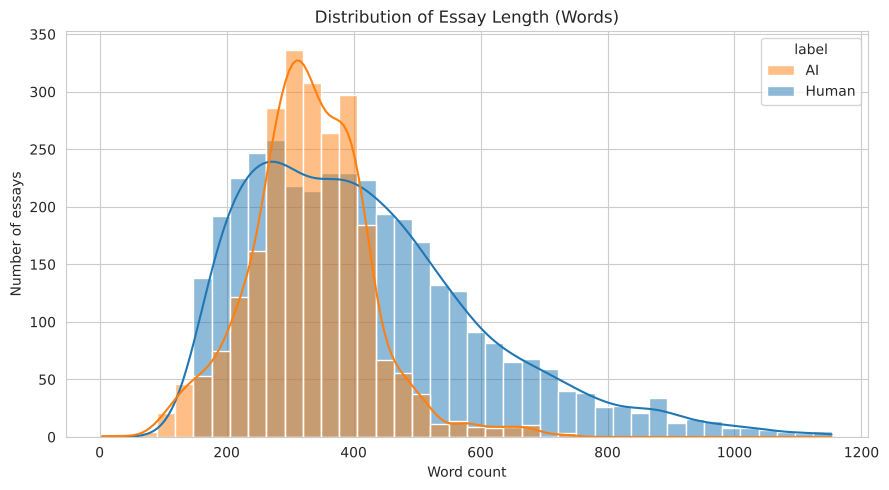

In [7]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df[df['word_count'] < 1200], x='word_count', hue='label', palette=colors, bins=40, kde=True, alpha=0.5)
plt.title('Distribution of Essay Length (Words)')
plt.xlabel('Word count')
plt.ylabel('Number of essays')
plt.tight_layout()
plt.savefig('images/02_word_count_hist.png', dpi=150)
plt.show()

**What it shows:** how long essays are in each group (very long outliers above 1200 words are cut off for readability). **Insight:** compare where the two peaks sit and how wide each one is. A narrower peak means the writing length is more consistent. **Use:** length alone is a weak clue, but it can be one signal for a detector.

## 5. Average word length by label

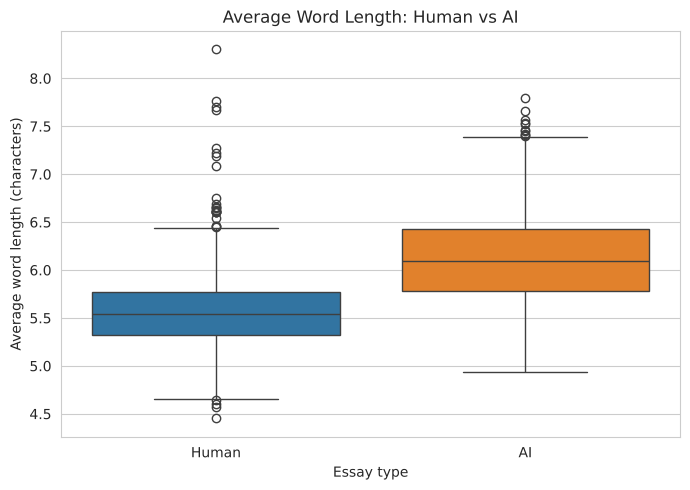

In [8]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df[df['avg_word_len'] < 9], x='label', y='avg_word_len', hue='label', palette=colors, legend=False, order=['Human', 'AI'])
plt.title('Average Word Length: Human vs AI')
plt.xlabel('Essay type')
plt.ylabel('Average word length (characters)')
plt.tight_layout()
plt.savefig('images/03_avg_word_len_box.png', dpi=150)
plt.show()

**What it shows:** the typical word length in each group and any outliers. **Insight:** the AI box sits higher, so AI essays use longer words on average (this measure counts spaces too, so it is a little above real word length; a few broken essays with very long 'words' are left out of this plot). **Use:** teachers could notice unusually formal vocabulary, though it is not proof on its own.

## 6. Vocabulary variety (unique-word ratio)

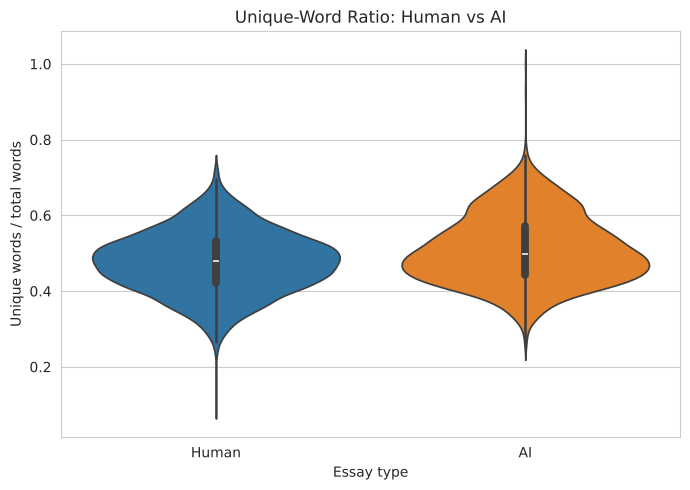

In [9]:
plt.figure(figsize=(7, 5))
sns.violinplot(data=df, x='label', y='unique_ratio', hue='label', palette=colors, legend=False, order=['Human', 'AI'])
plt.title('Unique-Word Ratio: Human vs AI')
plt.xlabel('Essay type')
plt.ylabel('Unique words / total words')
plt.tight_layout()
plt.savefig('images/04_unique_ratio_violin.png', dpi=150)
plt.show()

**What it shows:** how repetitive each group's writing is. **Insight:** a higher ratio means more varied words. Note that this ratio also drops for longer essays, so it is partly linked to length. **Use:** shows why features should be read together, not one at a time.

## 7. Word count vs unique-word ratio

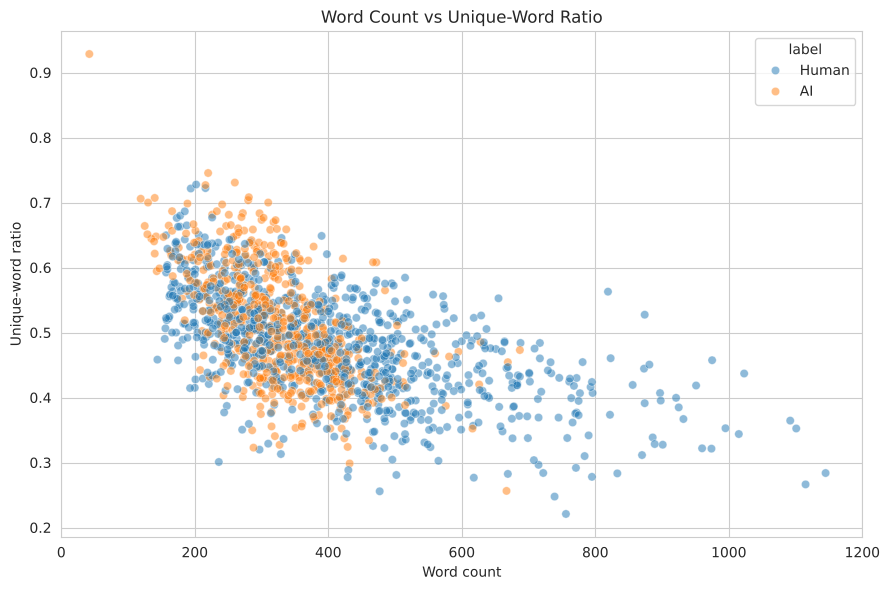

In [10]:
sample = df.sample(1500, random_state=1)   # smaller sample so the plot is readable
plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample, x='word_count', y='unique_ratio', hue='label', palette=colors, alpha=0.5)
plt.xlim(0, 1200)
plt.title('Word Count vs Unique-Word Ratio')
plt.xlabel('Word count')
plt.ylabel('Unique-word ratio')
plt.tight_layout()
plt.savefig('images/05_scatter.png', dpi=150)
plt.show()

**What it shows:** the relationship between essay length and vocabulary variety, with colors for each group. **Insight:** longer essays have lower unique ratios in both groups. Look at whether one color sits above the other at the same length. **Use:** comparing at similar lengths is fairer than comparing raw averages.

## 8. Correlation between features

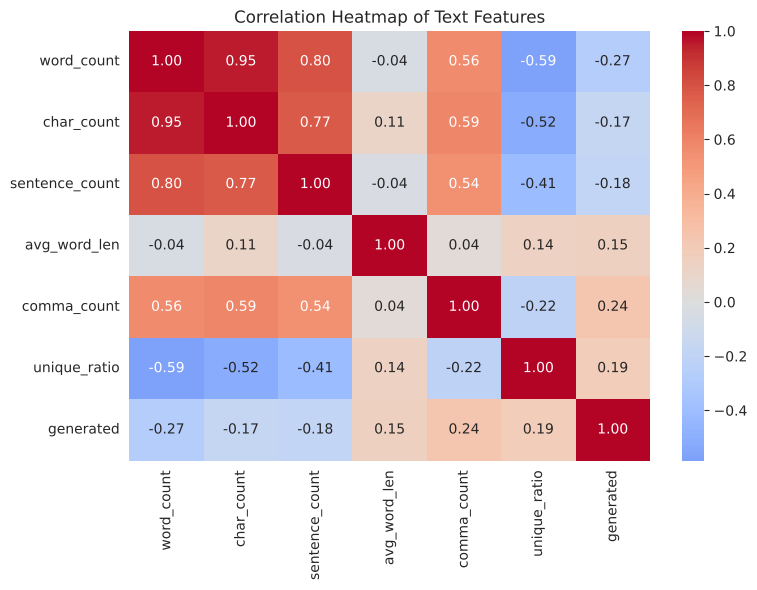

In [11]:
plt.figure(figsize=(8, 6))
corr = df[features + ['generated']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Text Features')
plt.tight_layout()
plt.savefig('images/06_heatmap.png', dpi=150)
plt.show()

**What it shows:** how the features relate to each other and to the AI label (`generated`). **Insight:** word count, char count and sentence count are strongly linked to each other, so they carry similar information. **Use:** when building a model, you can drop some of the repeated features.

## 9. Top 10 most common words

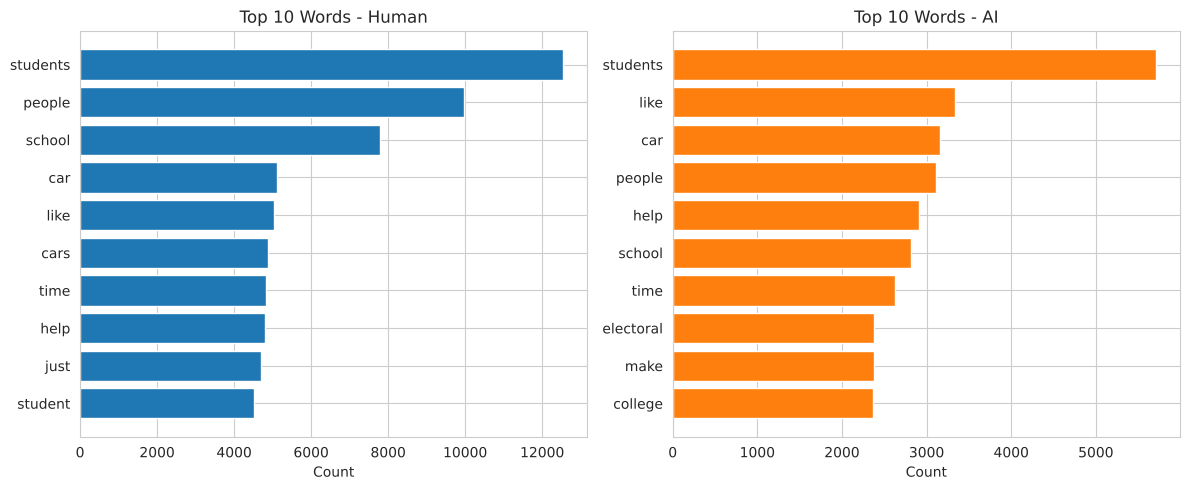

In [12]:
def top_words(texts, n=10):
    words = re.findall(r'[a-z]+', ' '.join(texts).lower())
    words = [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return Counter(words).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, lab in zip(axes, ['Human', 'AI']):
    w = top_words(df[df['label'] == lab]['text'])
    ax.barh([x[0] for x in w][::-1], [x[1] for x in w][::-1], color=colors[lab])
    ax.set_title(f'Top 10 Words - {lab}')
    ax.set_xlabel('Count')
plt.tight_layout()
plt.savefig('images/07_top_words.png', dpi=150)
plt.show()

**What it shows:** the most common words (stopwords removed) in each group. **Insight:** many top words depend on the essay topics, so overlap is likely. Differences in words like 'can', 'also' or topic words can hint at style. **Use:** a detector could use word patterns, but topic bias must be watched.

## 10. Commas and sentence length

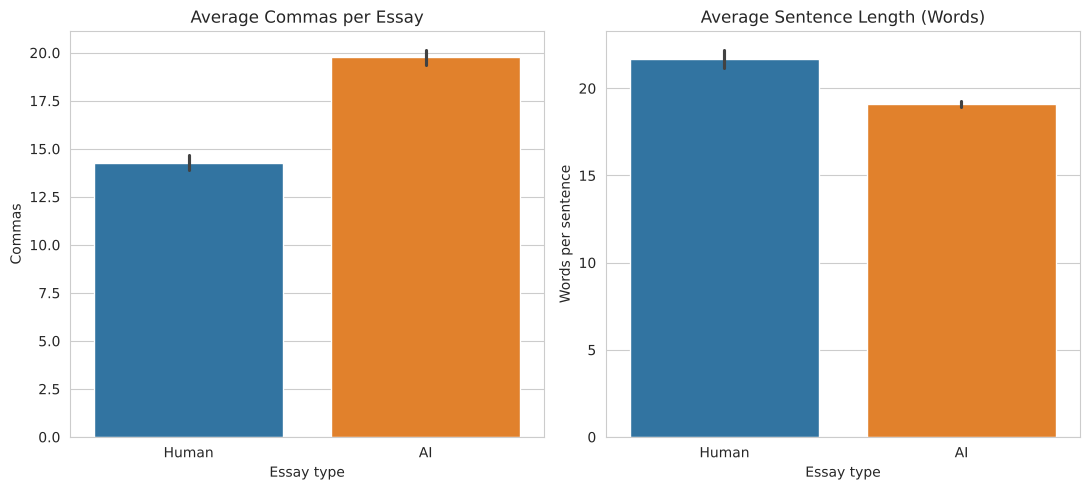

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sns.barplot(data=df, x='label', y='comma_count', hue='label', palette=colors, legend=False, order=['Human', 'AI'], ax=axes[0])
axes[0].set_title('Average Commas per Essay')
axes[0].set_xlabel('Essay type')
axes[0].set_ylabel('Commas')
sns.barplot(data=df, x='label', y='avg_sentence_len', hue='label', palette=colors, legend=False, order=['Human', 'AI'], ax=axes[1])
axes[1].set_title('Average Sentence Length (Words)')
axes[1].set_xlabel('Essay type')
axes[1].set_ylabel('Words per sentence')
plt.tight_layout()
plt.savefig('images/08_punctuation.png', dpi=150)
plt.show()

**What it shows:** punctuation use and sentence length for both groups. **Insight:** check which group writes longer sentences and uses more commas. **Use:** writing style habits like these can help tell the groups apart.

## 11. Dashboard: main findings in one picture

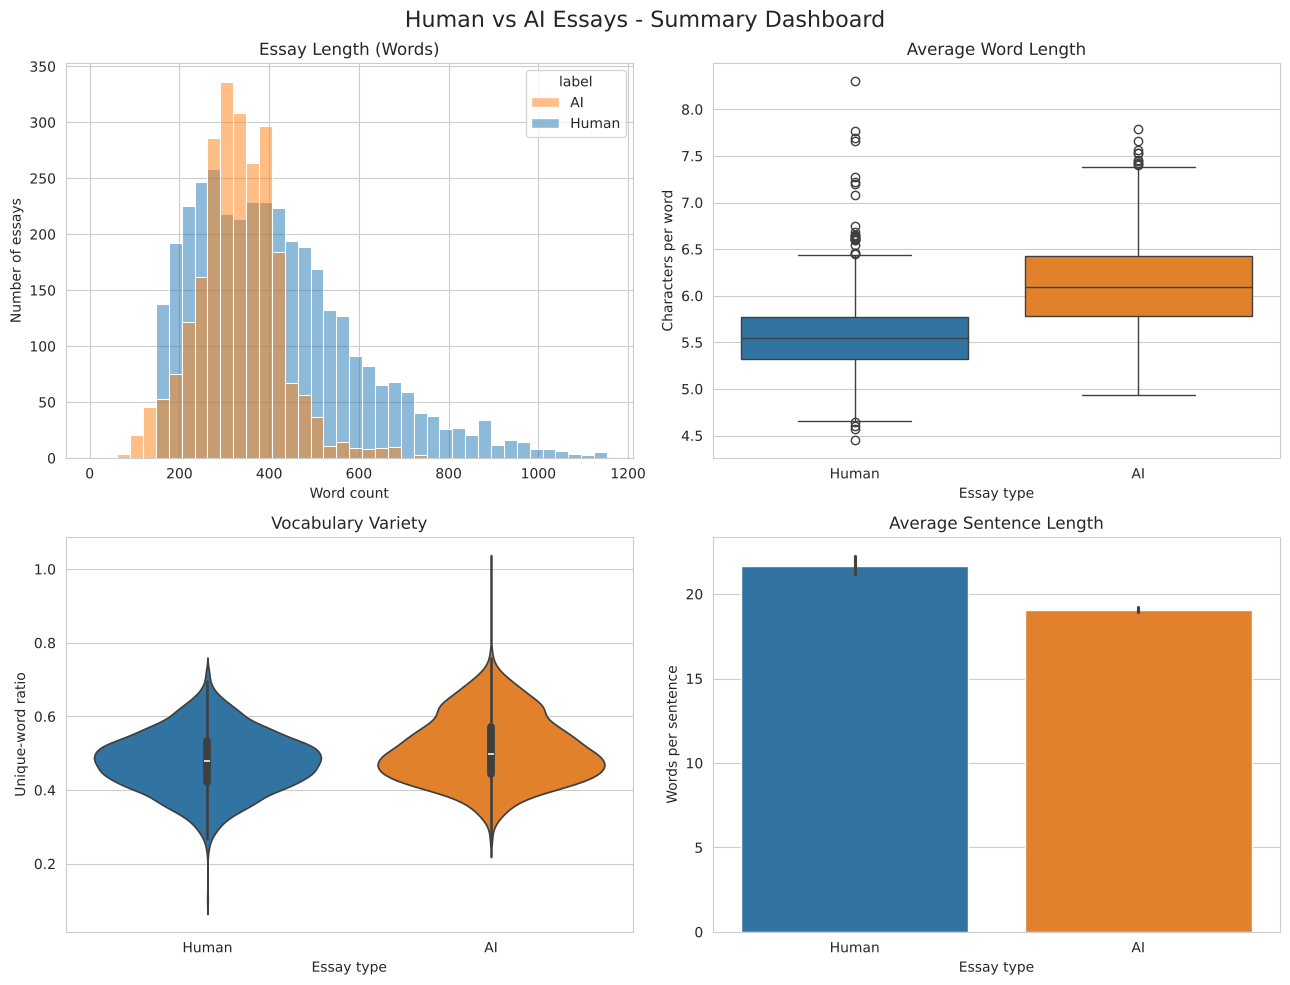

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle('Human vs AI Essays - Summary Dashboard', fontsize=16)

sns.histplot(data=df[df['word_count'] < 1200], x='word_count', hue='label', palette=colors, bins=40, alpha=0.5, ax=axes[0, 0])
axes[0, 0].set_title('Essay Length (Words)')
axes[0, 0].set_xlabel('Word count')
axes[0, 0].set_ylabel('Number of essays')

sns.boxplot(data=df[df['avg_word_len'] < 9], x='label', y='avg_word_len', hue='label', palette=colors, legend=False, order=['Human', 'AI'], ax=axes[0, 1])
axes[0, 1].set_title('Average Word Length')
axes[0, 1].set_xlabel('Essay type')
axes[0, 1].set_ylabel('Characters per word')

sns.violinplot(data=df, x='label', y='unique_ratio', hue='label', palette=colors, legend=False, order=['Human', 'AI'], ax=axes[1, 0])
axes[1, 0].set_title('Vocabulary Variety')
axes[1, 0].set_xlabel('Essay type')
axes[1, 0].set_ylabel('Unique-word ratio')

sns.barplot(data=df, x='label', y='avg_sentence_len', hue='label', palette=colors, legend=False, order=['Human', 'AI'], ax=axes[1, 1])
axes[1, 1].set_title('Average Sentence Length')
axes[1, 1].set_xlabel('Essay type')
axes[1, 1].set_ylabel('Words per sentence')

plt.tight_layout()
plt.savefig('images/09_dashboard.png', dpi=150)
plt.show()

## 12. Conclusion

In [15]:
print(df.groupby('label')[['word_count','avg_word_len','unique_ratio','avg_sentence_len','comma_count']].mean().round(2))

       word_count  avg_word_len  unique_ratio  avg_sentence_len  comma_count
label                                                                       
AI         330.34          6.15          0.51             19.08        19.76
Human      419.27          5.59          0.48             21.66        14.28


- Human essays are longer on average (about 419 words vs 330 for AI), and they use longer sentences (about 22 words vs 19).
- AI essays use more commas (about 20 vs 14 per essay) even though they are shorter, so their sentences are packed with more clauses.
- AI essays have a longer average word length (6.15 vs 5.59 characters per word, spaces included), which suggests more formal vocabulary.
- The unique-word ratio is only slightly higher for AI (0.51 vs 0.48). Part of this is because AI essays are shorter, so I would not read too much into it.
- No single feature separates the two groups cleanly: the distributions overlap a lot. A detector would need to combine several features, and a teacher should not judge an essay on one clue alone.